**Célula 1 – setup:**


In [1]:
import os
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

%load_ext autoreload
%autoreload 2

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.utils import set_seed, SEED
from src.color_data import prepare_color_subset, get_color_splits, COLOR_TYPES, COLOR_COLOURS

set_seed()

**Célula 2 – criar o subconjunto (na 1.ª vez demora alguns minutos por causa do download):**

In [2]:
start = time.perf_counter()
images, types, colours = prepare_color_subset()
print(f"Pronto em {time.perf_counter() - start:.1f} s")
print("images:", images.shape, images.dtype, "| min =", images.min(), "max =", images.max())

c:\Users\andre\OneDrive\Documentos\UBI\ML\PROJETO2\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\andre\OneDrive\Documentos\UBI\ML\PROJETO2\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\andre\.cache\huggingface\hub\datasets--ashraq--fashion-product-images-small. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to

Pronto em 24.5 s
images: (2704, 28, 28, 3) uint8 | min = 0 max = 255


**Célula 3 – quantas imagens por tipo e cor:**

In [3]:
counts = pd.crosstab(pd.Series(types, name="type"), pd.Series(colours, name="colour"))
print(counts.to_string())
print("Total:", len(types))
counts.to_csv("results/tables/14a_color_subset_counts.csv")

X_gal, t_gal, c_gal, X_q, t_q, c_q = get_color_splits()
print("Galeria:", X_gal.shape, "| Queries:", X_q.shape)

colour        Black  Blue  Green  Red  White  Yellow
type                                                
Casual Shoes    100   100     79  100    100      19
Handbags        100   100     93  100     68      29
Shirts          100   100    100  100    100      57
Tops            100   100    100   92    100      67
Tshirts         100   100    100  100    100     100
Total: 2704
Galeria: (2163, 2352) | Queries: (541, 2352)


**Célula 4 – grelha de exemplos (uma imagem por tipo × cor):**

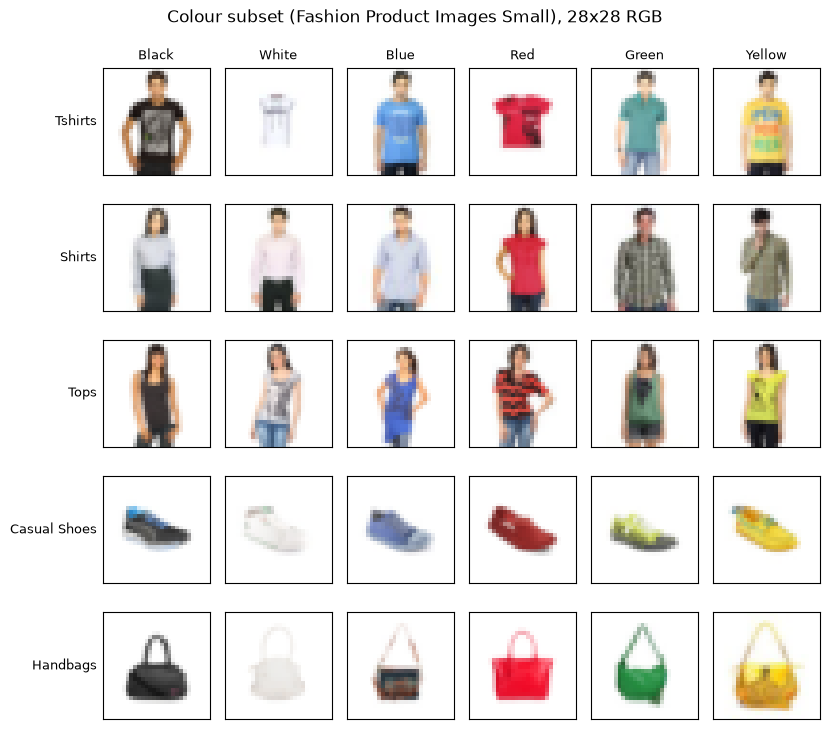

In [4]:
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(len(COLOR_TYPES), len(COLOR_COLOURS),
                         figsize=(len(COLOR_COLOURS) * 1.4, len(COLOR_TYPES) * 1.5))
for r, t in enumerate(COLOR_TYPES):
    for c, col in enumerate(COLOR_COLOURS):
        ax = axes[r, c]
        idx = np.where((types == t) & (colours == col))[0]
        if len(idx) > 0:
            ax.imshow(images[rng.choice(idx)])                  
        ax.set_xticks([]); ax.set_yticks([])
        if r == 0:
            ax.set_title(col, fontsize=9)
        if c == 0:
            ax.set_ylabel(t, fontsize=9, rotation=0, ha="right", va="center")
plt.suptitle("Colour subset (Fashion Product Images Small), 28x28 RGB")
plt.tight_layout()
plt.savefig("results/figures/14a_color_subset_examples.png", dpi=150, bbox_inches="tight")
plt.show()